## License

- This notebook is an **original implementation** licensed under the repository default license, **MIT** (see `LICENSE` and `LICENSING.md`).
- It is inspired by the CNES/CESBIO **Let-it-snow (LIS)** algorithm. No LIS code or parameter file is copied. The thresholds are cited from Gascoin et al. (2019), Table 1.
- Scientific source: Gascoin, S., Grizonnet, M., Bouchet, M., Salgues, G., and Hagolle, O. (2019). *Theia Snow collection: high-resolution operational snow cover maps from Sentinel-2 and Landsat-8 data.* Earth System Science Data, 11, 493–514. https://doi.org/10.5194/essd-11-493-2019
- LIS code (Apache-2.0): https://gitlab.orfeo-toolbox.org/remote_modules/let-it-snow
- Implementation: Development Seed (openEO-UDP project)

# Snow cover in the Pyrenees with openEO: a Let-it-snow-like processing chain

*Workshop "Utilisation d'openEO", GEODES Tools Days, CNES, Toulouse, 13 October 2026.*

The talk showed a 10-line teaser: compute the NDSI on Sentinel-2 L2A, apply the threshold NDSI > 0.4, and take the mean over time. This gives a snow cover fraction. This notebook turns the teaser into a processing chain that is close to **Let-it-snow (LIS)**, the algorithm behind the Theia snow products. Each step adds **one openEO concept**:

| Step | What we compute | openEO concept |
|---|---|---|
| 0 | Discover the backend | STAC metadata: collections, bands, processes |
| 1 | Teaser: NDSI and snow cover fraction | Process graph, lazy evaluation, `download` compared with batch jobs |
| 2 | Cloud and no-data masking with SCL | `mask`, boolean cubes, no-data semantics |
| 3 | LIS pass 1: NDSI **and** red | Callbacks on the band dimension, runtime `Parameter`s |
| 4 | DEM, snowline and LIS pass 2 | Multi-collection cubes: `resample_cube_spatial`, `merge_cubes` |
| 5 | Snow cover duration (SCD) over a hydrological year | Temporal aggregation, gap filling along `t`, batch jobs |
| 6 | Snow cover per watershed | Vector cubes, `aggregate_spatial` |
| 7 | *Optional:* a UDF for the per-image snowline | `run_udf` (CDSE only) |
| | Export the algorithm as a UDP | User-defined process and APEx record |

Each step ends with a short **exercise** (2–5 minutes). Click on "Solution" to see a solution.

**Backends.** The notebook runs on the Copernicus Data Space Ecosystem (**CDSE**) by default. It also runs on **TiTiler-openEO on Microsoft Planetary Computer** (`mpc`), with the differences listed in the facilitator notes at the end. Change `ENDPOINT` in the configuration cell to switch.

## Scientific background: Let-it-snow in one page

LIS (Gascoin et al., 2019) classifies each cloud-free pixel of a Sentinel-2 L2A image as *snow* or *no snow*. The main index is the Normalized Difference Snow Index (Dozier, 1989; Hall et al., 1995):

$$
NDSI = \frac{\rho_{green} - \rho_{SWIR}}{\rho_{green} + \rho_{SWIR}} = \frac{B03 - B11}{B03 + B11}
$$

Snow is bright in the visible and dark in the short-wave infrared, so its NDSI is high.

1. **Pass 1.** A pixel is snow if $NDSI > n_1$ **and** $\rho_{red} > r_1$. The red test removes dark surfaces with a high NDSI, for example water and some shadows.
2. **Snowline.** The DEM is cut into elevation bands of $dz$ = 100 m. Band $b$ is the lowest band where the snow fraction of the clear pixels is more than $f_s$, and where the clear fraction is more than $f_{ct}$. The snowline elevation $z_s$ is the lower edge of band $b-2$.
3. **Pass 2.** Above $z_s$, LIS uses lower thresholds: a pixel is snow if $NDSI > n_2$ **and** $\rho_{red} > r_2$. This recovers snow in shade on the high slopes.
4. **Clouds.** LIS uses the MAJA cloud mask and reclassifies some "dark" clouds.

Default values (Gascoin et al., 2019, Table 1, p. 499; the same defaults are in `doc/lis_default_configuration.json` of the LIS repository):

| Symbol | Meaning | Value |
|---|---|---|
| $n_1$ | Pass 1 NDSI threshold | 0.400 |
| $r_1$ | Pass 1 red reflectance threshold | 0.200 |
| $n_2$ | Pass 2 NDSI threshold | 0.150 |
| $r_2$ | Pass 2 red reflectance threshold | 0.040 |
| $dz$ | Elevation band height | 100 m |
| $f_s$ | Minimum snow fraction in a band to define the snowline | 0.100 |
| $f_{ct}$ | Minimum clear fraction in a band | 0.100 |
| $f_t$ | Minimum total snow fraction to run pass 2 | 0.001 |
| $r_D$ | Dark cloud red threshold (cloud mask refinement) | 0.300 |
| $r_B$ | "Back to cloud" red threshold | 0.100 |

### Where this workshop version is simpler than LIS

| LIS | This notebook | Why |
|---|---|---|
| MAJA L2A (Theia) with its cloud mask | Sen2Cor L2A with the SCL layer | Sen2Cor L2A is the collection that openEO backends serve |
| Dark-cloud test ($r_D$, $r_B$, resize factor 12) | Not implemented | SCL has no MAJA-like cloud mask to refine |
| Slope-corrected reflectance from MAJA | Sen2Cor flat-surface reflectance | Product difference |
| One snowline $z_s$ per image | Step 4: $z_s$ per image is computed and plotted, but the exported UDP takes **one** $z_s$ per run as a parameter. Step 7 shows a per-image $z_s$ in a UDF | A per-image scalar from a histogram cannot be expressed easily with standard processes |
| Pass 2 runs only if the pass 1 snow fraction is more than $f_t$ | Not tested | Same reason |
| SCD with a ±15-day margin and a 0/1 threshold of the daily interpolated snow | Daily linear interpolation and a threshold of 0.5, without a margin | Simplicity |
| 20 m processing | 20 m processing (`target_resolution`) | Same |

## Setup

Import the libraries. `ParameterManager` loads the parameter sets from `lis_snow_cover.params.py` and maps the canonical collection and band names to the names of the selected backend.

In [1]:
import time
from datetime import date as Date, timedelta
from functools import reduce
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray
from openeo.processes import and_, if_, or_

from openeo_udp import ParameterManager

In [2]:
_algorithm_id = "lis_snow_cover"

# Change these two values to switch the backend or the area.
ENDPOINT = "copernicus_dataspace"  # or "mpc" (TiTiler-openEO on Planetary Computer)
PARAM_SET = "neouvielle_pyrenees_france"  # or "canigou_pyrenees_france"

OUT = Path(f"{_algorithm_id}_outputs") / ENDPOINT
OUT.mkdir(parents=True, exist_ok=True)

param_manager = ParameterManager(f"{_algorithm_id}.params.py")
param_manager.print_options("LIS-like snow cover")

Available parameter sets for LIS-like snow cover:
  1. neouvielle_pyrenees_france: Néouvielle massif, Hautes-Pyrénées, France
  2. canigou_pyrenees_france: Canigou massif, Pyrénées-Orientales, France

Available OpenEO endpoints:
  1. eopf_explorer: https://api.explorer.eopf.copernicus.eu/openeo
  2. copernicus_dataspace: https://openeo.dataspace.copernicus.eu/
  3. ds_development: https://openeo.ds.io/
  4. mpc: https://openeo.mpc.ds.io/
  5. localhost_dev: http://localhost:8082/

💡 Tip: Use param_manager.interactive_parameter_selection() for interactive selection,
or param_manager.quick_connect('set_name', 'endpoint') for direct connection.
To change selections, use the interactive widgets in the next cell.


In [3]:
connection, current_params = param_manager.quick_connect(
    param_set=PARAM_SET,
    endpoint=ENDPOINT,
)

# Backend-intrinsic values: never hard-code them.
SCALE = current_params["reflectance_scale"]  # 10000.0 for integer L2A
BANDS_DIM = current_params["bands_dimension"]  # "bands" on CDSE, "spectral" on MPC
T_DIM = current_params["time_dimension"]

# Canonical band name -> native band name, and its index in the loaded cube.
bands = param_manager.band_name_map(current_params)
IDX = {name: i for i, name in enumerate(bands)}
print(bands, IDX)

🔄 Connecting to copernicus_dataspace...
📍 Using parameter set: neouvielle_pyrenees_france
Authenticated using refresh token.
✅ Successfully connected to copernicus_dataspace
✅ Parameters loaded and mapped for: Néouvielle massif, Hautes-Pyrénées, France
🔄 Parameters mapped for endpoint copernicus_dataspace:
  collection: sentinel-2-l2a -> SENTINEL2_L2A
  bands: ['b03', 'b04', 'b11', 'scl'] -> ['B03', 'B04', 'B11', 'SCL']
{'b03': 'B03', 'b04': 'B04', 'b11': 'B11', 'scl': 'SCL'} {'b03': 0, 'b04': 1, 'b11': 2, 'scl': 3}


### Facilitator helper: time and credits per step

This cell is not part of openEO. It records the wall-clock time of each step and the credits that CDSE reports in the `OpenEO-Costs-experimental` response header of each synchronous request. Batch jobs report their cost in the job metadata.

In [4]:
RUN_LOG = []


def _record_costs(response, *args, **kwargs):
    cost = response.headers.get("OpenEO-Costs-experimental")
    if cost is not None and RUN_LOG:
        RUN_LOG[-1]["credits"] += float(cost)


connection.session.hooks["response"].append(_record_costs)


class step:
    # Context manager: `with step("1 teaser"): ...` records time and credits.
    def __init__(self, name):
        self.name = name

    def __enter__(self):
        RUN_LOG.append({"step": self.name, "seconds": 0.0, "credits": 0.0})
        self.t0 = time.perf_counter()

    def __exit__(self, *exc):
        RUN_LOG[-1]["seconds"] = round(time.perf_counter() - self.t0, 1)
        print(f"[{self.name}] {RUN_LOG[-1]['seconds']} s, {RUN_LOG[-1]['credits']} credits")

## Step 0 – Discover the backend

An openEO backend describes itself. Its collections are STAC collections with a `cube:dimensions` description, and its processes are listed with their JSON schemas. A client must **discover** what the backend offers. It must not assume it. This is also how this notebook finds the band names and the dimension names.

In [5]:
with step("0 discovery"):
    collection_ids = connection.list_collection_ids()
    process_ids = {p["id"] for p in connection.list_processes()}
    s2_meta = connection.describe_collection(current_params["collection"].default)

print(f"{len(collection_ids)} collections, {len(process_ids)} processes")
print("Sentinel-2:", [c for c in collection_ids if "2" in c and "sentinel" in c.lower()])

dims = s2_meta["cube:dimensions"]
print("Dimensions:", {name: d["type"] for name, d in dims.items()})
print("Bands:", dims[BANDS_DIM]["values"])
print("Time extent:", dims[T_DIM].get("extent"))

[0 discovery] 1.2 s, 0.0 credits
137 collections, 146 processes
Sentinel-2: ['SENTINEL_5P_L2', 'SENTINEL3_SYN_L2_SYN', 'SENTINEL3_SLSTR_L2_LST', 'SENTINEL5P_L2_CO', 'SENTINEL5P_L2_NO2', 'SENTINEL5P_L2_CH4', 'SENTINEL2_L2A', 'SENTINEL2_L1C', 'SENTINEL3_OLCI_L2_LAND', 'SENTINEL3_OLCI_L2_WATER', 'SENTINEL3_SYN_L2_AOD', 'SENTINEL5P_L2_SO2', 'SENTINEL5P_L2_HCHO', 'SENTINEL5P_L2_O3', 'SENTINEL5P_L2_AER_LH', 'SENTINEL5P_L2_AER_AI', 'SENTINEL5P_L2_CLOUD']
Dimensions: {'bands': 'bands', 't': 'temporal', 'x': 'spatial', 'y': 'spatial'}
Bands: ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B11', 'B12', 'WVP', 'AOT', 'SCL', 'sunAzimuthAngles', 'sunZenithAngles', 'viewAzimuthMean', 'viewZenithMean', 'CLD', 'SNW']
Time extent: ['2015-06-27T10:25:31Z', None]


In [6]:
# Which of the processes used in this notebook does this backend have?
needed = [
    "load_collection", "resample_spatial", "reduce_dimension", "mask",
    "merge_cubes", "resample_cube_spatial", "add_dimension", "aggregate_temporal",
    "aggregate_temporal_period", "array_interpolate_linear", "aggregate_spatial",
    "run_udf",
]
pd.Series({p: p in process_ids for p in needed}, name="available").to_frame()

,available
load_collection,True
resample_spatial,True
reduce_dimension,True
mask,True
merge_cubes,True
resample_cube_spatial,True
add_dimension,True
aggregate_temporal,True
aggregate_temporal_period,True
array_interpolate_linear,True


**Exercise 0 (2 min).** Find the digital elevation model (DEM) collection of this backend and the name of its band.

<details><summary>Solution</summary>

```python
dem_ids = [c for c in collection_ids if "dem" in c.lower() or "COPERNICUS_30" in c]
print(dem_ids)  # CDSE: COPERNICUS_30 ... ; MPC: cop-dem-glo-30 ...
dem_meta = connection.describe_collection(dem_ids[0])
print({k: v.get("values") for k, v in dem_meta["cube:dimensions"].items()})
# CDSE: band "DEM" on dimension "bands"; MPC: band "data" on dimension "spectral"
```

The canonical name `cop-dem-glo-30` / `dem` in `lis_snow_cover.params.py` hides this difference. See `openeo_udp/endpoints/*.py`.
</details>

## Step 1 – Teaser: NDSI and snow cover fraction

This is the code of the talk slide. Three openEO ideas:

- **The process graph.** Each Python call adds a node to a graph. Nothing runs yet (*lazy evaluation*).
- **Runtime parameters.** The area, the period, the cloud cover and the NDSI threshold are `Parameter` objects. The graph keeps `{"from_parameter": ...}` references, so the same graph can later be exported as a reusable process (UDP). `param_manager.resolve()` replaces the references with values before a synchronous request.
- **Reflectance scale.** The NDSI is a ratio, so the scale (`SCALE`) cancels out. We use it from step 3, where the red threshold needs reflectance.

In [7]:
s2 = connection.load_collection(
    current_params["collection"].default,  # intrinsic -> literal
    spatial_extent=current_params["bounding_box"],  # runtime -> Parameter
    temporal_extent=current_params["time"],
    bands=current_params["bands"].default,
    properties={"eo:cloud_cover": lambda x: x <= current_params["cloud_cover"]},
)
# LIS works on the 20 m grid of B11.
s2 = s2.resample_spatial(resolution=current_params["target_resolution"].default)

green = s2.band(bands["b03"])
swir = s2.band(bands["b11"])
ndsi = (green - swir) / (green + swir)

snow_teaser = (ndsi > current_params["ndsi_pass1"]) * 1.0  # 1 = snow, 0 = no snow
scf_teaser = snow_teaser.reduce_dimension(dimension=T_DIM, reducer="mean")

# Nothing has run yet: we only have a graph.
graph = scf_teaser.flat_graph()
print(f"{len(graph)} nodes:", [node["process_id"] for node in graph.values()])

4 nodes: ['load_collection', 'resample_spatial', 'reduce_dimension', 'reduce_dimension']


`download()` sends the graph to `POST /result` and waits for the answer (**synchronous**). This is good for small areas and fast feedback. For larger jobs, `execute_batch()` creates a **batch job** that runs in the background and stores its results (step 5). Both take the same graph.

[1 teaser] 23.8 s, 7.0 credits


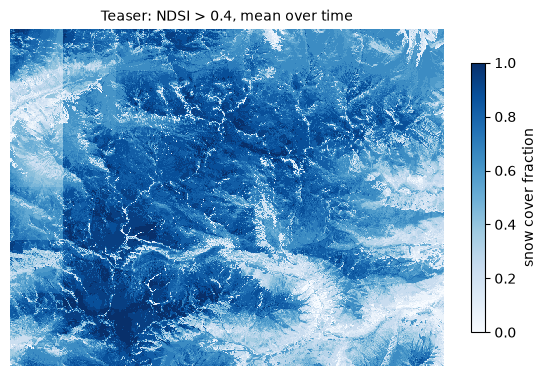

Mean snow cover fraction: 0.62


In [8]:
def plot_map(ax, da, title, cmap="Blues", vmin=0, vmax=1, label="snow cover fraction"):
    # Null pixels (no clear observation, or outside the area) are grey.
    cmap = plt.get_cmap(cmap).copy()
    cmap.set_bad("lightgrey")
    im = ax.imshow(np.ma.masked_invalid(da), cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    plt.colorbar(im, ax=ax, shrink=0.7, label=label)


with step("1 teaser"):
    path = OUT / "step1_teaser.tif"
    param_manager.resolve(scf_teaser, current_params).download(path)

scf1 = rioxarray.open_rasterio(path).squeeze()
fig, ax = plt.subplots(figsize=(7, 5))
plot_map(ax, scf1, f"Teaser: NDSI > {current_params['ndsi_pass1'].default}, mean over time")
plt.show()
print(f"Mean snow cover fraction: {float(scf1.mean()):.2f}")

**Exercise 1 (3 min).** Change the NDSI threshold to 0.2 and the period to February 2023 **without changing the graph**. Pass other values to `resolve()`.

<details><summary>Solution</summary>

```python
other = {**current_params, "ndsi_pass1": 0.2, "time": ["2023-02-01", "2023-02-28"]}
param_manager.resolve(scf_teaser, other).download(OUT / "step1_exercise.tif")
plot_map(plt.gca(), rioxarray.open_rasterio(OUT / "step1_exercise.tif").squeeze(), "NDSI > 0.2, February")
```

The graph is the same. Only the parameter values change. This is what makes a UDP reusable.
</details>

## Step 2 – Cloud and no-data masking

The teaser has two problems:

1. **Clouds** have a low NDSI, so cloudy dates count as "no snow".
2. **No data** also counts as "no snow". The Néouvielle area is on the edge of one Sentinel-2 orbit: on half of the dates, part of the area has no data. In `if_`, `null` counts as `false`.

The snow cover fraction must be **snow dates / clear dates**, not snow dates / all dates. In openEO:

- `mask(data, mask)` replaces the pixels of `data` where `mask` is true (or non-zero) with **null**.
- The reducers (`mean`, `count`, ...) **ignore null** values. The mean of a masked cube is therefore snow dates / clear dates.

LIS uses the MAJA cloud mask. CDSE and MPC serve the Sen2Cor L2A, so we use its scene classification layer (SCL). A pixel is **usable** only if its SCL class is in a positive list. A positive list is safer than a list of cloud classes, because a pixel without data (`null`) is then unusable automatically:

| SCL | Class | Usable? |
|---|---|---|
| 0 | No data | no |
| 1 | Saturated or defective | no |
| 2 | Dark area pixels (often topographic shadow) | yes |
| 3 | Cloud shadows | no |
| 4, 5, 6, 7 | Vegetation, not vegetated, water, unclassified | yes |
| 8, 9, 10 | Cloud medium probability, cloud high probability, thin cirrus | no |
| 11 | Snow or ice | yes |

SCL also has its own **snow class (11)**. We compare it with the NDSI result.

In [9]:
USABLE_SCL = [2, 4, 5, 6, 7, 11]


def unusable_pixel(x):
    # 0 for a usable observation, 1 for cloud, shadow, defect or no data.
    scl = x[IDX["scl"]]
    is_usable = reduce(or_, [scl == c for c in USABLE_SCL])
    return if_(is_usable, 0, 1)  # null (no data) -> 1


unusable = s2.reduce_dimension(dimension=BANDS_DIM, reducer=unusable_pixel)

snow_clear = snow_teaser.mask(unusable)  # 1 / 0 / null
scf_clear = snow_clear.reduce_dimension(dimension=T_DIM, reducer="mean")
n_clear = snow_clear.reduce_dimension(dimension=T_DIM, reducer="count")

scl_snow = (s2.band(bands["scl"]) == 11) * 1.0
scf_scl = scl_snow.mask(unusable).reduce_dimension(dimension=T_DIM, reducer="mean")


def as_band(cube, label):
    # Give a cube without a band dimension a named band, so that it can be merged.
    return cube.add_dimension(name=BANDS_DIM, label=label, type="bands")


step2 = (
    as_band(scf_teaser, "all_dates")
    .merge_cubes(as_band(scf_clear, "clear_dates"))
    .merge_cubes(as_band(scf_scl, "scl_snow"))
    .merge_cubes(as_band(n_clear, "n_clear"))
)

[2 masking] 31.2 s, 7.0 credits


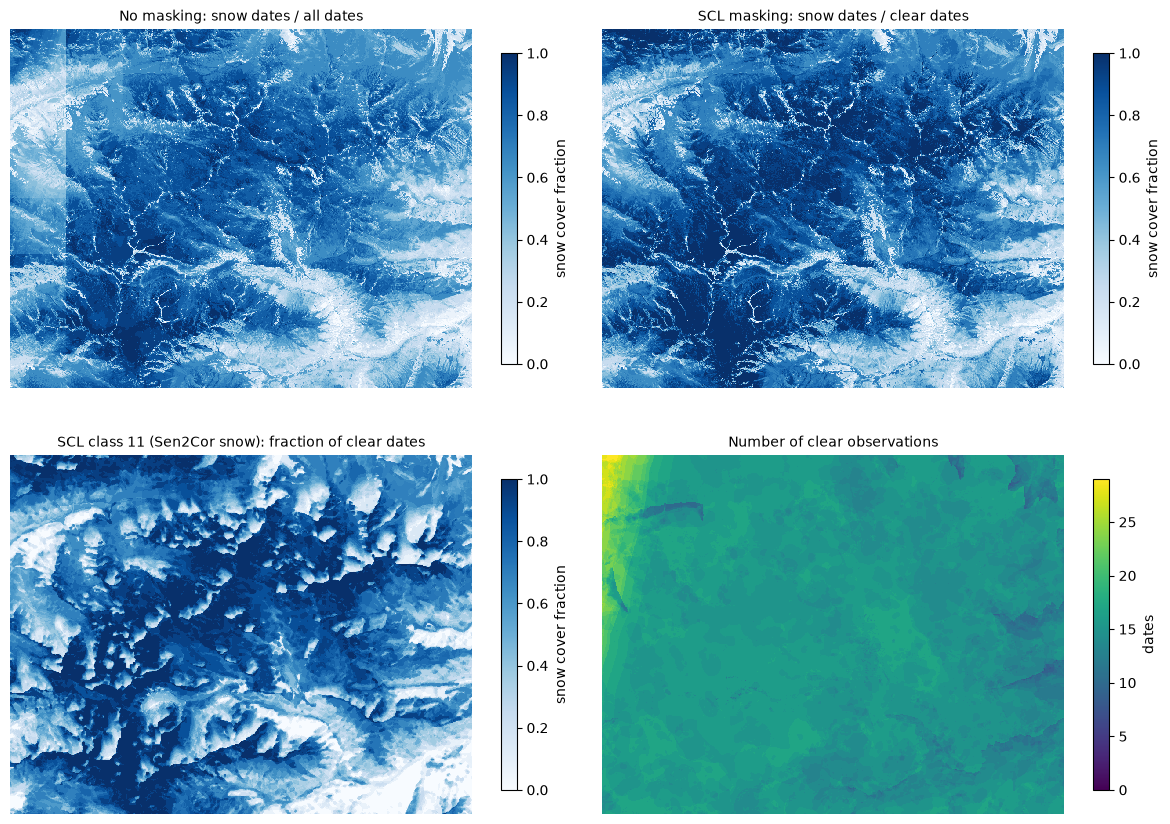

Mean snow cover fraction, no masking : 0.62
Mean snow cover fraction, SCL masking: 0.70
Mean snow cover fraction, SCL class 11: 0.65


In [10]:
with step("2 masking"):
    path = OUT / "step2_masking.tif"
    param_manager.resolve(step2, current_params).download(path)

r2 = rioxarray.open_rasterio(path)
all_dates, clear_dates, scl_frac, nclear = (r2.isel(band=i) for i in range(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
plot_map(axes[0, 0], all_dates, "No masking: snow dates / all dates")
plot_map(axes[0, 1], clear_dates, "SCL masking: snow dates / clear dates")
plot_map(axes[1, 0], scl_frac, "SCL class 11 (Sen2Cor snow): fraction of clear dates")
plot_map(axes[1, 1], nclear, "Number of clear observations", cmap="viridis",
         vmin=0, vmax=float(nclear.max()), label="dates")
plt.tight_layout()
plt.show()

print(f"Mean snow cover fraction, no masking : {float(all_dates.mean()):.2f}")
print(f"Mean snow cover fraction, SCL masking: {float(clear_dates.mean()):.2f}")
print(f"Mean snow cover fraction, SCL class 11: {float(scl_frac.mean()):.2f}")

**Exercise 2 (3 min).** In mountains, Sen2Cor often labels terrain shadows as cloud shadows (class 3). Add class 3 to `USABLE_SCL`, run the cells again and compare the number of clear observations and the snow cover fraction.

<details><summary>Solution</summary>

```python
USABLE_SCL = [2, 3, 4, 5, 6, 7, 11]
# Re-run the two cells above. n_clear increases on the north-facing slopes, and
# the snow fraction there changes, because shadowed snow has a low red reflectance.
```

Set `USABLE_SCL` back to `[2, 4, 5, 6, 7, 11]` afterwards.
</details>

## Step 3 – LIS pass 1: NDSI **and** red reflectance

LIS pass 1 adds a red test: snow if $NDSI > n_1$ **and** $\rho_{red} > r_1$. A threshold on reflectance needs real reflectance, so we divide by `SCALE`: 10000 for the integer L2A of CDSE, 1 on MPC, which already serves 0–1 reflectance. We never write `/ 10000` directly.

We write the band maths as Python functions. openEO converts each one to a **callback**: a small process graph that `reduce_dimension` runs on the band values of each pixel (`x` is the array of bands, in the order of `bands`).

The thresholds are runtime parameters, and we compare them **at cube level** (`ndsi > n1`), not inside the band callback. Both forms give the same result in a synchronous request. But when the graph runs as a UDP, CDSE fails if a band callback uses a UDP parameter (found while preparing this workshop). `&` and `|` between two cubes become `merge_cubes` with an `and` / `or` overlap resolver.

[3 pass 1] 52.5 s, 7.0 credits


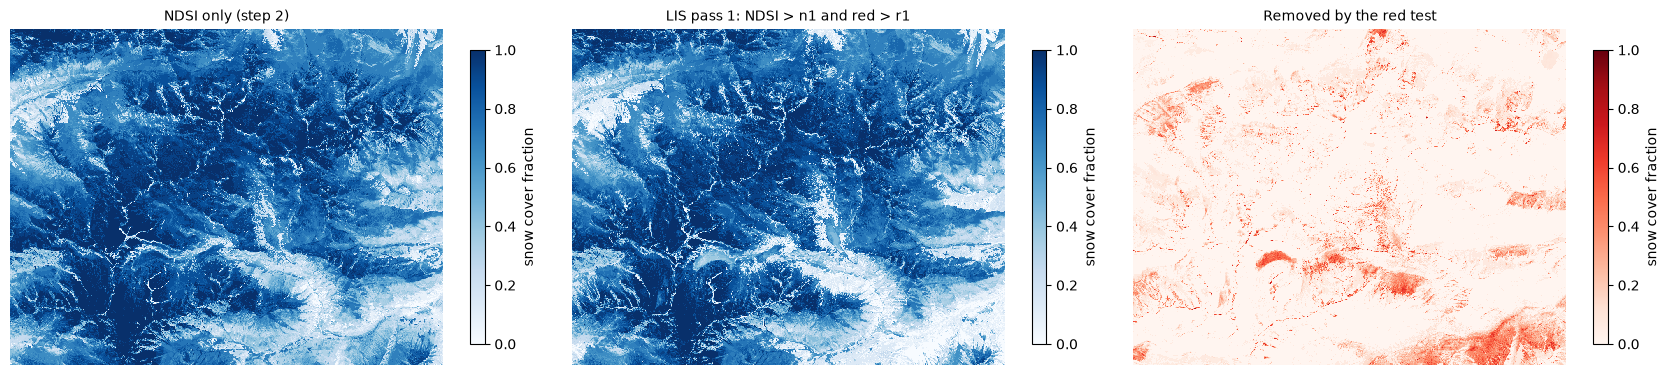

In [11]:
def ndsi_fn(x):
    green = x[IDX["b03"]] / SCALE
    swir = x[IDX["b11"]] / SCALE
    return (green - swir) / (green + swir)


def red_fn(x):
    return x[IDX["b04"]] / SCALE


def lis_tests(s2_):
    # Boolean cubes of the LIS pass 1 and pass 2 spectral tests (no elevation yet).
    ndsi_ = s2_.reduce_dimension(dimension=BANDS_DIM, reducer=ndsi_fn)
    red_ = s2_.reduce_dimension(dimension=BANDS_DIM, reducer=red_fn)
    pass1 = (ndsi_ > current_params["ndsi_pass1"]) & (red_ > current_params["red_pass1"])
    pass2 = (ndsi_ > current_params["ndsi_pass2"]) & (red_ > current_params["red_pass2"])
    return pass1, pass2


pass1, pass2 = lis_tests(s2)
snow_p1 = (pass1 * 1.0).mask(unusable)
scf_p1 = snow_p1.reduce_dimension(dimension=T_DIM, reducer="mean")

with step("3 pass 1"):
    path = OUT / "step3_pass1.tif"
    param_manager.resolve(scf_p1, current_params).download(path)

scf3 = rioxarray.open_rasterio(path).squeeze()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_map(axes[0], clear_dates, "NDSI only (step 2)")
plot_map(axes[1], scf3, "LIS pass 1: NDSI > n1 and red > r1")
plot_map(axes[2], clear_dates - scf3, "Removed by the red test", cmap="Reds",
         label="snow cover fraction")
plt.tight_layout()
plt.show()

The red test removes snow mainly on lakes (high NDSI, low red reflectance) and in deep shadow. LIS recovers the shadowed snow with pass 2, above the snowline.

**Exercise 3 (3 min).** Run pass 1 with $r_1$ = 0.1 and with $r_1$ = 0.3. Where does the snow cover fraction change most?

<details><summary>Solution</summary>

```python
for r1 in (0.1, 0.3):
    param_manager.resolve(scf_p1, {**current_params, "red_pass1": r1}).download(OUT / f"step3_r1_{r1}.tif")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, r1 in zip(axes, (0.1, 0.3)):
    plot_map(ax, rioxarray.open_rasterio(OUT / f"step3_r1_{r1}.tif").squeeze(), f"r1 = {r1}")
```

The changes are on north-facing slopes and in valleys, where the sun is low in winter.
</details>

## Step 4 – Add the terrain: DEM, snowline and LIS pass 2

Now we use a **second collection**, the Copernicus DEM GLO-30:

1. `load_collection` of the DEM. Its canonical id is mapped to the backend id, like the Sentinel-2 collection.
2. The DEM has a nominal time dimension. We remove it with `reduce_dimension(t, max)`.
3. `resample_cube_spatial` puts the DEM on the Sentinel-2 grid (UTM, 20 m).
4. `merge_cubes` combines the cubes. We first reduce the snow cube over time (there is one date per request here), so that both cubes have the same dimensions `(bands, y, x)`. Some backends can also broadcast a cube without `t` to all dates, but not all of them (TiTiler-openEO cannot), and we want this graph to run everywhere.

The Sentinel-2 cube is a rectangle in UTM that contains the longitude/latitude bounding box. The DEM is cut to the bounding box itself, so the corners of the UTM rectangle (about 7 % of the pixels) have no elevation. These pixels are outside the requested area.

Then we compute the snow fraction per 100 m elevation band, as LIS does, for a few clear dates. The download is one small request per date: the graph is the same, only `time` changes.

In [12]:
dem_params = param_manager.apply_endpoint_mapping(
    {"collection": current_params["dem_collection"], "bands": current_params["dem_bands"]},
    ENDPOINT,
)
print(dem_params["collection"].default, dem_params["bands"].default)

dem = connection.load_collection(
    dem_params["collection"].default,
    spatial_extent=current_params["bounding_box"],
    bands=dem_params["bands"].default,
)
dem_native = dem.reduce_dimension(dimension=T_DIM, reducer="max")  # DEM on its own grid
dem = dem_native.resample_cube_spatial(target=s2, method="bilinear")
DEM_BAND = dem_params["bands"].default[0]

snow_one_date = snow_p1.reduce_dimension(dimension=T_DIM, reducer="max")
snow_and_dem = as_band(snow_one_date, "snow").merge_cubes(dem)  # bands: snow, elevation

COPERNICUS_30 ['DEM']


In [15]:
def next_day(day):
    return (Date.fromisoformat(day) + timedelta(days=1)).isoformat()


snowline_dates = current_params["snowline_dates"].default
per_date = {}
with step("4 snow + DEM per date"):
    for date in snowline_dates:
        path = OUT / f"step4_snow_dem_{date}.tif"
        values = {**current_params, "time": [date, next_day(date)]}
        param_manager.resolve(snow_and_dem, values).download(path)
        per_date[date] = rioxarray.open_rasterio(path, masked=True)

print(per_date[snowline_dates[0]])

[4 snow + DEM per date] 47.0 s, 21.0 credits
<xarray.DataArray (band: 2, y: 817, x: 1052)> Size: 7MB
[1718968 values with dtype=float32]
Coordinates:
  * band         (band) int64 16B 1 2
  * x            (x) float64 8kB 7.489e+05 7.49e+05 ... 7.699e+05 7.7e+05
  * y            (y) float64 7kB 4.757e+06 4.757e+06 ... 4.741e+06 4.741e+06
    spatial_ref  int64 8B 0
Attributes:
    PROCESSING_SOFTWARE:  0.73.0a20
    AREA_OR_POINT:        Area
    scale_factor:         1.0
    add_offset:           0.0
    long_name:            ('snow', 'DEM')


The snowline, as in LIS (Gascoin et al., 2019, Sect. 2.4.2, and `compute_snowline` in the LIS code):

- The elevation bands start at the DEM minimum and are $dz$ = 100 m high.
- Band $b$ is the **lowest** band where clear / all > $f_{ct}$ = 0.1 and snow / clear > $f_s$ = 0.1.
- $z_s$ is the lower edge of band $\max(b-2, 0)$.

This is client-side Python on a small result: a good example of the split between openEO (heavy pixels) and the notebook (small statistics).

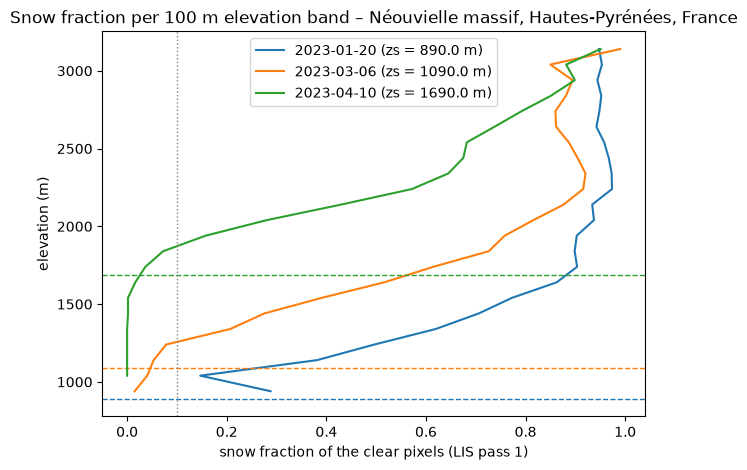

Snowline zs per date: {'2023-01-20': 890.0, '2023-03-06': 1090.0, '2023-04-10': 1690.0}


In [16]:
DZ, FS, FCT = 100, 0.1, 0.1  # LIS defaults (Gascoin et al., 2019, Table 1)


def snow_by_elevation(da, dz=DZ):
    # da: band 1 = snow (1 / 0 / null), band 2 = elevation
    snow = da.isel(band=0).values.ravel()
    z = da.isel(band=1).values.ravel()
    ok = np.isfinite(z)
    snow, z = snow[ok], z[ok]
    edges = np.arange(np.floor(z.min()), z.max() + dz, dz)
    band = np.digitize(z, edges) - 1
    rows = []
    for b in range(len(edges) - 1):
        in_band = band == b
        total = in_band.sum()
        clear = np.isfinite(snow[in_band]).sum()
        n_snow = np.nansum(snow[in_band])
        rows.append({
            "z_low": edges[b], "z_mid": edges[b] + dz / 2, "total": total,
            "clear_frac": clear / total if total else np.nan,
            "snow_frac": n_snow / clear if clear else np.nan,
        })
    return pd.DataFrame(rows)


def lis_snowline(table, fs=FS, fct=FCT):
    hit = table[(table.clear_frac > fct) & (table.snow_frac > fs)]
    if hit.empty:
        return None  # no snowline: LIS keeps the pass 1 result
    b = hit.index[0]
    return float(table.loc[max(b - 2, 0), "z_low"])


tables = {d: snow_by_elevation(ds) for d, ds in per_date.items()}
snowlines = {d: lis_snowline(t) for d, t in tables.items()}

fig, ax = plt.subplots(figsize=(7, 5))
for (d, t), color in zip(tables.items(), ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    ax.plot(t.snow_frac, t.z_mid, color=color, label=f"{d} (zs = {snowlines[d]} m)")
    if snowlines[d] is not None:
        ax.axhline(snowlines[d], color=color, ls="--", lw=1)
ax.axvline(FS, color="grey", ls=":", lw=1)
ax.set_xlabel("snow fraction of the clear pixels (LIS pass 1)")
ax.set_ylabel("elevation (m)")
ax.set_title(f"Snow fraction per {DZ} m elevation band – {current_params['location_name']}")
ax.legend()
plt.show()
print("Snowline zs per date:", snowlines)

### LIS pass 2

Above $z_s$ a pixel is snow if it passes pass 1 **or** if $NDSI > n_2$ **and** $\rho_{red} > r_2$, with the lower pass 2 thresholds.

The elevation test does not change in time. So we do not need the DEM on every date: for each pixel,

$$
\overline{snow}_{LIS} = \begin{cases} \overline{pass_1 \lor pass_2} & \text{if } z > z_s \\ \overline{pass_1} & \text{otherwise} \end{cases}
$$

where the bar is the mean over the clear dates. We compute the two time means, **then** combine them with a 0/1 "above the snowline" cube: $\overline{pass_1} + (\overline{pass_1 \lor pass_2} - \overline{pass_1}) \times above$. This is exact, it makes the graph smaller, and it avoids a `merge_cubes` between a cube with `t` and a cube without `t`.

We apply the elevation threshold on the native DEM grid and resample the 0/1 result afterwards. The other order gives the same result in a synchronous request, but CDSE returns wrong values when the graph runs as a UDP (found while preparing this workshop).

LIS computes $z_s$ per image. A per-image value that comes from a histogram of the whole image cannot easily be expressed with standard openEO processes, so this version takes **one** $z_s$ per run as a runtime parameter, `snowline_elevation`. Here we use the median of the snowlines of the dates above. Step 7 (optional) shows the per-image snowline in a UDF.

This cube, `lis_snow_cover`, is the algorithm that we export as a UDP at the end. It returns two bands: the snow cover fraction (snow dates / clear dates) and the number of clear observations.

In [17]:
def apply_snowline(below, above, dem_native_, target):
    # Per pixel: `above` where the elevation is higher than zs, `below` elsewhere.
    is_above = (dem_native_ > current_params["snowline_elevation"]) * 1.0
    is_above = is_above.resample_cube_spatial(target=target, method="near").band(DEM_BAND)
    return below + (above - below) * is_above


def time_mean(cube):
    return cube.reduce_dimension(dimension=T_DIM, reducer="mean")


snow_p12 = ((pass1 | pass2) * 1.0).mask(unusable)
scf_lis = apply_snowline(time_mean(snow_p1), time_mean(snow_p12), dem_native, s2)
lis_snow_cover = as_band(scf_lis, "snow_cover_fraction").merge_cubes(
    as_band(snow_p1.reduce_dimension(dimension=T_DIM, reducer="count"), "clear_observations")
)

Snowline elevation used for this run: 1090.0 m (parameter default: 1100 m)
[4 LIS pass 1 + pass 2] 57.3 s, 7.0 credits


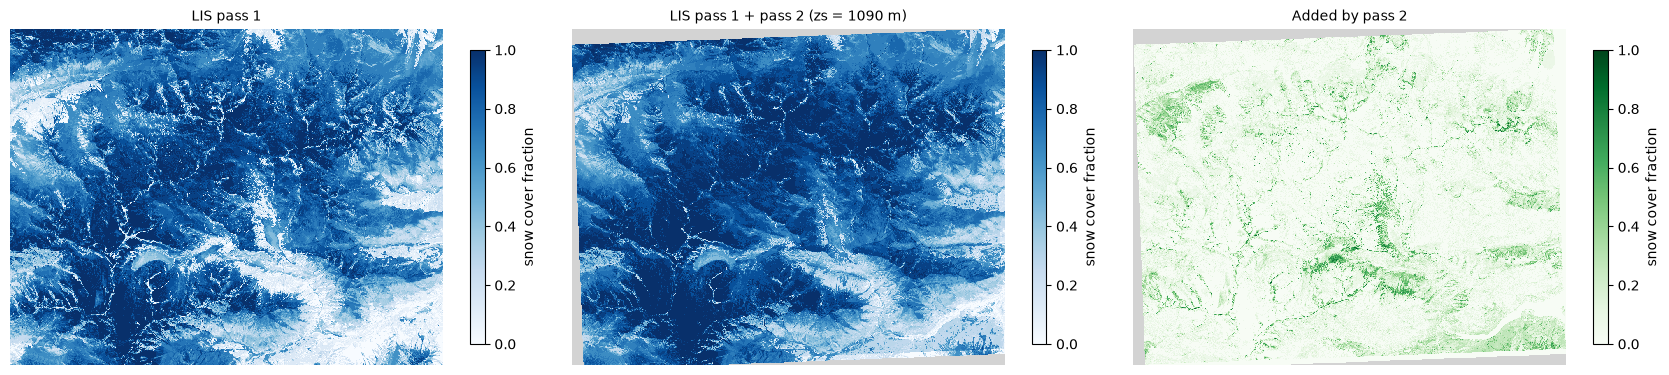

In [18]:
valid_snowlines = [z for z in snowlines.values() if z is not None]
zs_run = float(np.median(valid_snowlines)) if valid_snowlines else current_params["snowline_elevation"].default
print(f"Snowline elevation used for this run: {zs_run} m "
      f"(parameter default: {current_params['snowline_elevation'].default} m)")

with step("4 LIS pass 1 + pass 2"):
    path = OUT / "step4_lis_two_pass.tif"
    param_manager.resolve(lis_snow_cover, {**current_params, "snowline_elevation": zs_run}).download(path)

r4 = rioxarray.open_rasterio(path)
scf4 = r4.isel(band=0)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_map(axes[0], scf3, "LIS pass 1")
plot_map(axes[1], scf4, f"LIS pass 1 + pass 2 (zs = {zs_run:.0f} m)")
plot_map(axes[2], scf4 - scf3, "Added by pass 2", cmap="Greens")
plt.tight_layout()
plt.show()

**Exercise 4 (5 min).** Move to the other massif and compare the snowlines. The graph is parameterised, so you only change `bounding_box` and the dates.

<details><summary>Solution</summary>

```python
other_set = "canigou_pyrenees_france" if PARAM_SET.startswith("neouvielle") else "neouvielle_pyrenees_france"
other = param_manager.get_parameter_set(other_set)
other_tables = {}
for date in other["snowline_dates"].default:
    values = {**current_params, "bounding_box": other["bounding_box"], "time": [date, next_day(date)]}
    path = OUT / f"step4_other_{date}.tif"
    param_manager.resolve(snow_and_dem, values).download(path)
    other_tables[date] = snow_by_elevation(rioxarray.open_rasterio(path, masked=True))
print({d: lis_snowline(t) for d, t in other_tables.items()})
```

Canigou is closer to the Mediterranean. Its snowline is usually higher and changes faster than in the Néouvielle.
</details>

## Step 5 – Snow cover duration over a hydrological year

The LIS annual synthesis (`doc/snow_annual_map.md` and `snow_synthesis.py` in the LIS repository) computes the **snow cover duration (SCD)**: the number of snow days per pixel from 1 September to 31 August. LIS interpolates the snow maps linearly to a daily step, with the clouds as gaps, and sums the daily snow masks.

In openEO:

1. `aggregate_temporal` with **explicit daily intervals** gives one label per day, also for days without an acquisition. (On CDSE, `aggregate_temporal_period(period="day")` returns only the days that have data, so it cannot be used for gap filling.)
2. `apply_dimension` along `t` with `array_interpolate_linear` fills the gaps between clear observations. Values before the first and after the last clear observation stay null (no extrapolation).
3. A day is a snow day if the interpolated value is ≥ 0.5. The SCD is the sum over `t`.

One year of Sentinel-2 is too much for a synchronous request, so this step runs as a **batch job** on CDSE (`create_job` + `start_and_wait`; `execute_batch` does both in one call). The job runs in the background on the backend: you can close the notebook and get the results later with `connection.job(job_id)`. On MPC, which has no batch jobs, a monthly approximation at 100 m runs synchronously instead.

In [19]:
def lis_inputs(spatial_extent, temporal_extent, resolution=None):
    # Steps 1-4 in one function: Sentinel-2, DEM and the unusable-pixel mask.
    s2_ = connection.load_collection(
        current_params["collection"].default,
        spatial_extent=spatial_extent,
        temporal_extent=temporal_extent,
        bands=current_params["bands"].default,
        properties={"eo:cloud_cover": lambda x: x <= current_params["cloud_cover"]},
    ).resample_spatial(resolution=resolution or current_params["target_resolution"].default)
    dem_native_ = connection.load_collection(
        dem_params["collection"].default,
        spatial_extent=spatial_extent,
        bands=dem_params["bands"].default,
    ).reduce_dimension(dimension=T_DIM, reducer="max")
    dem_ = dem_native_.resample_cube_spatial(target=s2_, method="bilinear")
    unusable_ = s2_.reduce_dimension(dimension=BANDS_DIM, reducer=unusable_pixel)
    return s2_, dem_, unusable_, dem_native_


def snow_cubes(s2_, unusable_):
    # Pass 1 and "pass 1 or pass 2" snow cubes: 1 / 0 / null per date.
    pass1_, pass2_ = lis_tests(s2_)
    return (pass1_ * 1.0).mask(unusable_), ((pass1_ | pass2_) * 1.0).mask(unusable_)


year = current_params["hydrological_year"].default
day_edges = pd.date_range(year[0], year[1]).strftime("%Y-%m-%d")  # end date included
daily_intervals = [[a, b] for a, b in zip(day_edges[:-1], day_edges[1:])]
print(f"{len(daily_intervals)} days from {year[0]} to {year[1]} (excluded)")

s2_year, dem_year, unusable_year, dem_native_year = lis_inputs(
    current_params["bounding_box"], current_params["hydrological_year"]
)
p1_year, p12_year = snow_cubes(s2_year, unusable_year)
values_year = {**current_params, "snowline_elevation": zs_run}

365 days from 2022-09-01 to 2023-09-01 (excluded)


In [20]:
if ENDPOINT != "mpc":
    def snow_days(snow):
        daily = snow.aggregate_temporal(intervals=daily_intervals, reducer="mean")
        daily = daily.apply_dimension(dimension=T_DIM, process="array_interpolate_linear")
        return ((daily >= 0.5) * 1.0).reduce_dimension(dimension=T_DIM, reducer="sum")

    # Same idea as the pass 2 of step 4: the SCD is computed per pixel along t,
    # so the snowline can be applied after the time reduction.
    scd = apply_snowline(snow_days(p1_year), snow_days(p12_year), dem_native_year, s2_year)
    step5 = as_band(scd, "scd").merge_cubes(dem_year)

    with step("5 SCD (batch)"):
        job = param_manager.resolve(step5, values_year).create_job(
            title=f"LIS SCD {current_params['location_name']}", out_format="GTiff"
        )
        job.start_and_wait()
        job.get_results().download_files(OUT / "step5")
        RUN_LOG[-1]["credits"] += float(job.describe().get("costs") or 0)
    scd_path = next((OUT / "step5").glob("*.tif"))
else:
    # MPC: no batch jobs and no array_interpolate_linear. Monthly approximation at
    # 100 m: SCD ~ 365 x (mean of the 12 monthly snow cover fractions). The monthly
    # step gives each month the same weight, whatever its number of acquisitions.
    s2_year, dem_year, unusable_year, dem_native_year = lis_inputs(
        current_params["bounding_box"], current_params["hydrological_year"], resolution=100
    )
    p1_year, p12_year = snow_cubes(s2_year, unusable_year)
    months = pd.date_range(year[0], year[1], freq="MS").strftime("%Y-%m-%d")
    intervals = [[a, b] for a, b in zip(months[:-1], months[1:])]

    def snow_days(snow):
        monthly = snow.aggregate_temporal(intervals=intervals, reducer="mean")
        return monthly.reduce_dimension(dimension=T_DIM, reducer="mean") * 365

    scd = apply_snowline(snow_days(p1_year), snow_days(p12_year), dem_native_year, s2_year)
    step5 = as_band(scd, "scd").merge_cubes(dem_year)
    with step("5 SCD (monthly, synchronous)"):
        scd_path = OUT / "step5_scd_monthly.tif"
        param_manager.resolve(step5, values_year).download(scd_path)

r5 = rioxarray.open_rasterio(scd_path)
scd_map, z = r5.isel(band=0), r5.isel(band=1)

0:00:00 Job 'j-261011171708454b9ea001099d5cb037': send 'start'
0:00:02 Job 'j-261011171708454b9ea001099d5cb037': created (progress 0%)
0:00:07 Job 'j-261011171708454b9ea001099d5cb037': queued (progress 0%)
0:00:14 Job 'j-261011171708454b9ea001099d5cb037': queued (progress 0%)
0:00:22 Job 'j-261011171708454b9ea001099d5cb037': queued (progress 0%)
0:00:32 Job 'j-261011171708454b9ea001099d5cb037': queued (progress 0%)
0:00:45 Job 'j-261011171708454b9ea001099d5cb037': queued (progress 0%)
0:01:02 Job 'j-261011171708454b9ea001099d5cb037': queued (progress 0%)
0:01:21 Job 'j-261011171708454b9ea001099d5cb037': running (progress N/A)
0:01:45 Job 'j-261011171708454b9ea001099d5cb037': running (progress N/A)
0:02:15 Job 'j-261011171708454b9ea001099d5cb037': running (progress N/A)
0:02:53 Job 'j-261011171708454b9ea001099d5cb037': running (progress N/A)
0:03:40 Job 'j-261011171708454b9ea001099d5cb037': running (progress N/A)
0:04:38 Job 'j-261011171708454b9ea001099d5cb037': running (progress N/A)
0

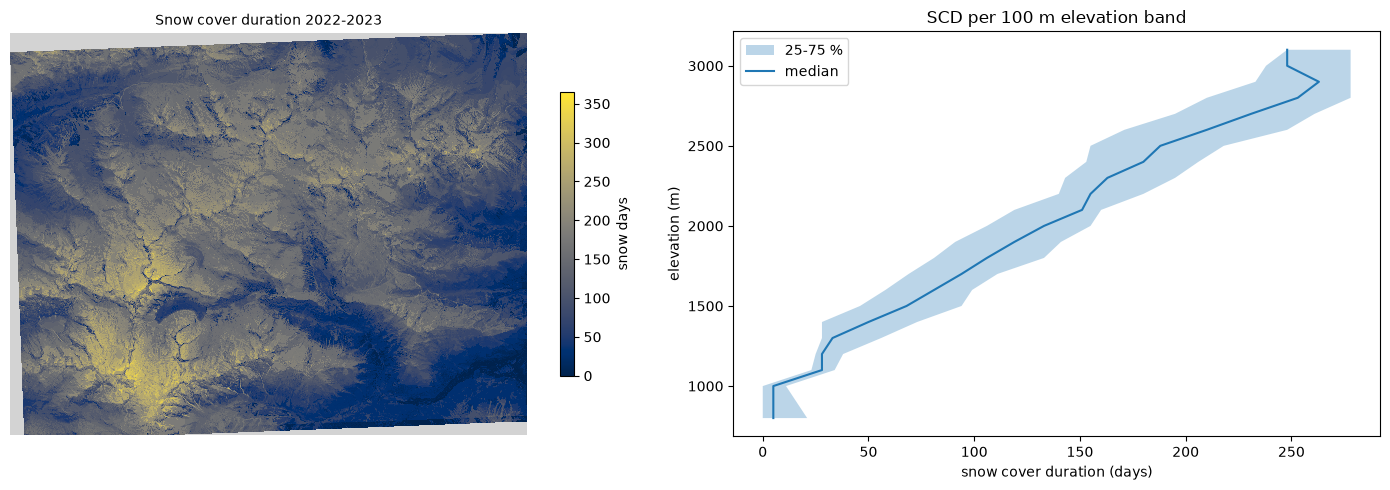

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_map(axes[0], scd_map, f"Snow cover duration {year[0][:4]}-{year[1][:4]}", cmap="cividis",
         vmin=0, vmax=365, label="snow days")
zb = (z.values.ravel() // DZ) * DZ
df5 = pd.DataFrame({"z": zb, "scd": scd_map.values.ravel()}).dropna()
stats = df5.groupby("z").scd.describe(percentiles=[0.25, 0.5, 0.75])
axes[1].fill_betweenx(stats.index, stats["25%"], stats["75%"], alpha=0.3, label="25-75 %")
axes[1].plot(stats["50%"], stats.index, label="median")
axes[1].set_xlabel("snow cover duration (days)")
axes[1].set_ylabel("elevation (m)")
axes[1].legend()
axes[1].set_title(f"SCD per {DZ} m elevation band")
plt.tight_layout()
plt.show()

**Exercise 5 (3 min).** How many snow days does a pixel at 2000 m have? And at 2500 m? Compare with the snow cover fraction of step 4: why can a pixel have a high snow cover fraction in January–May and a short SCD?

<details><summary>Solution</summary>

```python
print(stats.loc[[2000, 2500], ["25%", "50%", "75%"]])
```

The snow cover fraction of step 4 only covers January to May. The SCD covers the full year, and the snow season starts and ends at different dates at each elevation.
</details>

## Step 6 – Watersheds: from rasters to numbers

Hydrologists need numbers per watershed, not maps. `aggregate_spatial` reduces the pixels inside each polygon to one value per date and per band. The result is a **vector cube** (geometries × time × bands), which we download as CSV.

The watersheds are the BD TOPAGE topographic watersheds (Sandre / IGN / OFB, Licence Ouverte Etalab 2.0), simplified and stored next to this notebook. They are a runtime parameter of the graph, so you can pass your own polygons. We also load the data with the watersheds as `spatial_extent`, so that the cube covers the full watersheds, also where they go out of the bounding box.

For each date and watershed we compute:

- `snow`: the snow cover fraction of the clear pixels (LIS two-pass),
- `clear`: the fraction of the watershed that is clear.

The snow-covered area is then `snow × watershed area`. We keep only the dates where at least half of the watershed is clear.

In [22]:
s2_ws, dem_ws, unusable_ws, _ = lis_inputs(current_params["watersheds"], current_params["time"])
DEM_IDX = len(bands)  # the DEM is the band after b03, b04, b11, scl


def lis_two_pass(x):
    # Here we need the snow of every date, so the DEM goes inside the band callback.
    # This step is not exported as a UDP, so the thresholds can be in the callback.
    ndsi, red = ndsi_fn(x), red_fn(x)
    pass1 = and_(ndsi > current_params["ndsi_pass1"], red > current_params["red_pass1"])
    pass2 = and_(
        and_(ndsi > current_params["ndsi_pass2"], red > current_params["red_pass2"]),
        x[DEM_IDX] > current_params["snowline_elevation"],
    )
    return or_(pass1, pass2) * 1.0


# merge_cubes broadcasts the DEM (no t) to all dates: this works on CDSE.
snow_ws = s2_ws.merge_cubes(dem_ws).reduce_dimension(dimension=BANDS_DIM, reducer=lis_two_pass).mask(unusable_ws)
clear_ws = (unusable_ws == 0) * 1.0  # 1 = clear, 0 = cloud or no data (never null)
ws_cube = as_band(snow_ws, "snow").merge_cubes(as_band(clear_ws, "clear"))
ws_stats = ws_cube.aggregate_spatial(geometries=current_params["watersheds"], reducer="mean")

path = OUT / "step6_watersheds.csv"
if ENDPOINT == "mpc":
    print("Skipped on MPC: TiTiler-openEO cannot return a vector cube (no CSV/JSON output).")
else:
    with step("6 watersheds"):
        param_manager.resolve(ws_stats, {**current_params, "snowline_elevation": zs_run}).download(path, format="CSV")

df6 = pd.read_csv(path, parse_dates=["date"]) if path.exists() else None
print(df6.head() if df6 is not None else "No watershed statistics on this backend.")

[6 watersheds] 49.2 s, 7.0 credits
                       date  feature_index      snow     clear
0 2023-04-20 00:00:00+00:00              1  0.491091  0.375366
1 2023-04-20 00:00:00+00:00              0  0.536343  0.187488
2 2023-04-20 00:00:00+00:00              3  0.504863  0.460261
3 2023-04-18 00:00:00+00:00              2  0.025991  0.256391
4 2023-04-18 00:00:00+00:00              1       NaN  0.000000


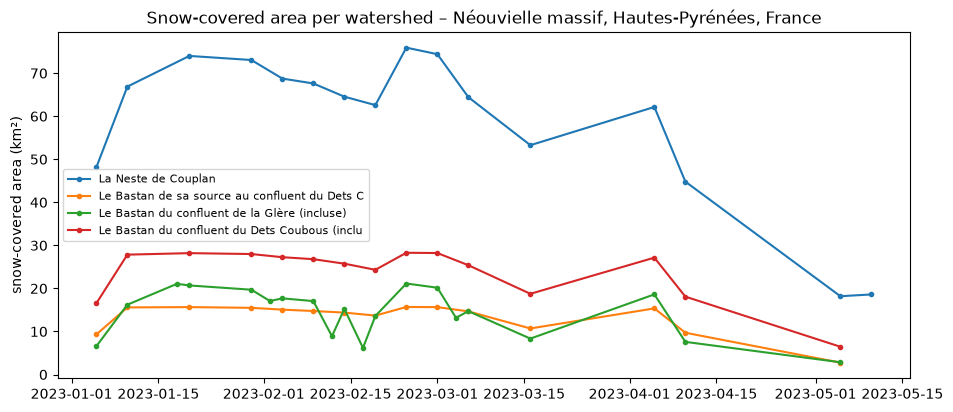

watershed,La Neste de Couplan,Le Bastan de sa source au confluent du Dets Coubous,Le Bastan du confluent de la Glère (incluse) au confluent du Bastan de Sers,Le Bastan du confluent du Dets Coubous (inclus) au confluent de la Glère
date,,,,
2023-01-05 00:00:00+00:00,48.1,9.3,6.6,16.5
2023-01-10 00:00:00+00:00,66.9,15.6,16.2,27.8
2023-01-18 00:00:00+00:00,NaN,NaN,21.1,NaN
2023-01-20 00:00:00+00:00,74.0,15.7,20.7,28.2
2023-01-30 00:00:00+00:00,73.1,15.5,19.7,28.0
2023-02-02 00:00:00+00:00,NaN,NaN,17.1,NaN
2023-02-04 00:00:00+00:00,68.7,15.1,17.7,27.3
2023-02-09 00:00:00+00:00,67.6,14.8,17.1,26.8
2023-02-12 00:00:00+00:00,NaN,NaN,8.9,NaN


In [23]:
MIN_CLEAR = 0.5
features = current_params["watersheds"].default["features"]
names = {i: f["properties"]["name"] for i, f in enumerate(features)}
areas = {i: f["properties"]["area_km2"] for i, f in enumerate(features)}

if df6 is not None:
    df6["watershed"] = df6["feature_index"].map(names)
    df6["area_km2"] = df6["feature_index"].map(areas)
    df6["sca_km2"] = df6["snow"] * df6["area_km2"]
    df6 = df6[df6["clear"] >= MIN_CLEAR].dropna(subset=["snow"]).sort_values("date")

    fig, ax = plt.subplots(figsize=(11, 4.5))
    for name, g in df6.groupby("watershed"):
        ax.plot(g["date"], g["sca_km2"], marker="o", ms=3, label=name[:45])
    ax.set_ylabel("snow-covered area (km²)")
    ax.set_title(f"Snow-covered area per watershed – {current_params['location_name']}")
    ax.legend(fontsize=8)
    plt.show()
    display(df6.pivot_table(index="date", columns="watershed", values="sca_km2").round(1).head(10))

**Exercise 6 (3 min).** Change the reducer of `aggregate_spatial` to `"median"` or `"max"`. Which reducer is correct for a snow cover fraction, and why?

<details><summary>Solution</summary>

`mean` of a 1/0 cube is the fraction of snow pixels, so `mean × area` is the snow-covered area. `max` only tells if there is at least one snow pixel. `median` tells if more than half of the clear pixels are snow.
</details>

## Step 7 (optional, advanced, CDSE only) – A per-image snowline with a UDF

In LIS, $z_s$ is computed **per image** from the histogram of that image, and pass 2 then uses that value. This is hard to express with standard processes, but easy in Python. `run_udf` runs Python code on the backend, next to the data. We call it in `apply_neighborhood` with a window that covers the whole area, so the UDF sees the full image of each date.

The price: a UDF only runs on backends with a Python UDF runtime (CDSE yes, TiTiler-openEO no), so it is **not** part of the exported UDP.

In [24]:
UDF_CODE = """
import numpy as np
import xarray as xr
from openeo.udf import XarrayDataCube


def apply_datacube(cube: XarrayDataCube, context: dict) -> XarrayDataCube:
    # bands: green, red, swir, scl, dem (reflectance as integers x scale)
    a = cube.get_array()
    scale, dz, fs, fct = context["scale"], context["dz"], context["fs"], context["fct"]
    n1, r1, n2, r2 = context["n1"], context["r1"], context["n2"], context["r2"]
    usable_scl = context["usable_scl"]
    out = []
    for t in a.coords["t"].values:
        img = a.sel(t=t)
        green, red, swir = (img.isel(bands=i).values / scale for i in range(3))
        scl, z = img.isel(bands=3).values, img.isel(bands=4).values
        with np.errstate(invalid="ignore", divide="ignore"):
            ndsi = (green - swir) / (green + swir)
        clear = np.isin(scl, usable_scl)
        pass1 = (ndsi > n1) & (red > r1)
        zs = None
        if np.isfinite(z).any():
            edges = np.arange(np.nanmin(z), np.nanmax(z) + dz, dz)
            band = np.digitize(z, edges) - 1
            for b in range(len(edges) - 1):
                in_b = band == b
                n_clear = (in_b & clear).sum()
                if in_b.sum() and n_clear / in_b.sum() > fct and (in_b & clear & pass1).sum() / n_clear > fs:
                    zs = edges[max(b - 2, 0)]
                    break
        snow = pass1.copy()
        if zs is not None:
            snow |= (ndsi > n2) & (red > r2) & (z > zs)
        result = np.where(clear, snow.astype("float32"), np.nan)
        out.append(np.stack([result] * a.sizes["bands"]))
    data = xr.DataArray(np.stack(out), dims=("t", "bands", "y", "x"), coords=a.coords)
    return XarrayDataCube(data)
"""

[7 UDF per-image snowline] 36.8 s, 7.0 credits


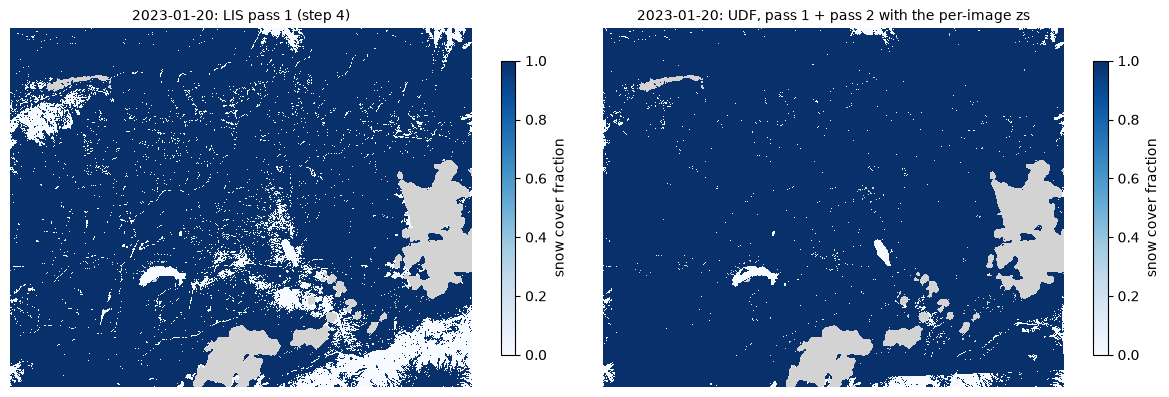

In [25]:
if "run_udf" in process_ids and ENDPOINT != "mpc":
    from openeo import UDF

    context = {
        "scale": SCALE, "dz": DZ, "fs": FS, "fct": FCT, "usable_scl": USABLE_SCL,
        **{k: current_params[p].default for k, p in
           [("n1", "ndsi_pass1"), ("r1", "red_pass1"), ("n2", "ndsi_pass2"), ("r2", "red_pass2")]},
    }
    date = snowline_dates[0]
    s2_one = connection.load_collection(
        current_params["collection"].default,
        spatial_extent=current_params["bounding_box"].default,
        temporal_extent=[date, next_day(date)],
        bands=current_params["bands"].default,
    ).resample_spatial(resolution=current_params["target_resolution"].default)
    dem_one = connection.load_collection(
        dem_params["collection"].default,
        spatial_extent=current_params["bounding_box"].default,
        bands=dem_params["bands"].default,
    ).reduce_dimension(dimension=T_DIM, reducer="max").resample_cube_spatial(target=s2_one, method="bilinear")
    udf_snow = s2_one.merge_cubes(dem_one).apply_neighborhood(
        process=UDF(code=UDF_CODE, runtime="Python", context=context),
        size=[{"dimension": "x", "value": 1280, "unit": "px"}, {"dimension": "y", "value": 1280, "unit": "px"}],
        overlap=[],
    ).band(bands["b03"])

    with step("7 UDF per-image snowline"):
        path = OUT / "step7_udf.tif"
        udf_snow.download(path)
    r7 = rioxarray.open_rasterio(path).squeeze()
    s4 = per_date[date].isel(band=0)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    plot_map(axes[0], s4, f"{date}: LIS pass 1 (step 4)")
    plot_map(axes[1], r7, f"{date}: UDF, pass 1 + pass 2 with the per-image zs")
    plt.tight_layout()
    plt.show()
else:
    print("Skipped: this backend has no run_udf.")

## Export the algorithm as a user-defined process (UDP)

The `lis_snow_cover` cube of step 4 is a **pure process graph** (no UDF). Its runtime parameters are still `{"from_parameter": ...}` references, because we only resolved copies of it. We export it as a UDP with an APEx catalogue record. Anyone can then run the same algorithm on another area, period or threshold set, on any backend that has the processes and the collections.

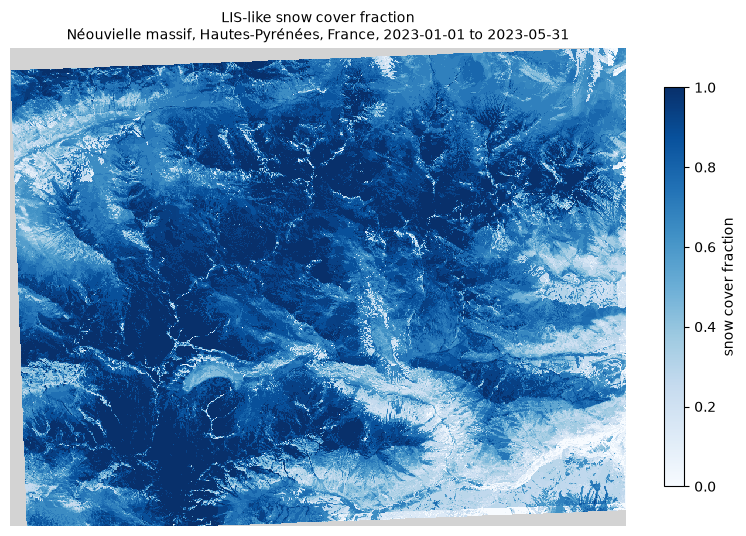

In [26]:
fig_preview, ax = plt.subplots(figsize=(8, 6))
plot_map(ax, scf4, f"LIS-like snow cover fraction\n{current_params['location_name']}, "
         f"{current_params['time'].default[0]} to {current_params['time'].default[1]}")
plt.tight_layout()
plt.show()

In [27]:
# Export necessary metadata to register the process graph in APEx Algorithm Catalogue
from pathlib import Path

from openeo_udp import ParameterManager
from openeo_udp.endpoints import get_endpoint_config

_algorithm_id = "lis_snow_cover"

_repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").exists())
_nb_href = f"{(Path.cwd() / f'{_algorithm_id}.ipynb').relative_to(_repo_root)}"

_param_set = "neouvielle_pyrenees_france"
_endpoint_name = "copernicus_dataspace"
_param_manager = ParameterManager(f"{_algorithm_id}.params.py")
_raw_params = _param_manager.get_parameter_set(_param_set)
_mapped_params = _param_manager.apply_endpoint_mapping(_raw_params, _endpoint_name)
_endpoint_config = get_endpoint_config(_endpoint_name)

metadata = {
    "id": _algorithm_id,
    "title": "LIS-like Snow Cover Fraction",
    "preview_title": "Snow cover fraction",
    "description": (
        "Snow cover fraction (number of snow dates divided by the number of clear dates) "
        "and number of clear observations from Sentinel-2 L2A, with a simplified version of "
        "the CNES/CESBIO Let-it-snow (LIS) algorithm: pass 1 (NDSI > n1 and red > r1), "
        "pass 2 above a snowline elevation (NDSI > n2 and red > r2) with the Copernicus "
        "DEM GLO-30, and a Sen2Cor SCL cloud and no-data mask. Original implementation "
        "inspired by Gascoin et al. (2019), ESSD 11, 493-514."
    ),
    "keywords": ["Sentinel-2", "Digital Elevation/Terrain Model (DEM)", "Climate"],
    "themes": ["CRYOSPHERE", "SNOW/ICE", "SNOW COVER"],
    "created": "2026-10-11T00:00:00Z",
    "updated": "2026-10-11T00:00:00Z",
    "license": "MIT",
    "openeo_backend_title": _endpoint_config["name"],
    "openeo_backend_url": _endpoint_config["url"],
    "notebook_github_location": _nb_href,
    "collection_id": _mapped_params["collection"].default,
    "attribution": {
        "original_script": "https://gitlab.orfeo-toolbox.org/remote_modules/let-it-snow",
        "authors": ["Simon Gascoin", "Manuel Grizonnet", "Marine Bouchet", "Germain Salgues", "Olivier Hagolle"],
        "source_repository": "https://gitlab.orfeo-toolbox.org/remote_modules/let-it-snow",
        "citation": [
            "Gascoin, S., Grizonnet, M., Bouchet, M., Salgues, G., and Hagolle, O. (2019). "
            "Theia Snow collection: high-resolution operational snow cover maps from "
            "Sentinel-2 and Landsat-8 data. Earth System Science Data, 11, 493-514. "
            "https://doi.org/10.5194/essd-11-493-2019",
        ],
    },
}

In [28]:
import json

from algorithm_registration.register_algorithm import register

assert ENDPOINT == _endpoint_name, "Export the UDP from a CDSE run: the preview and record target CDSE."

udp_parameters = [
    "bounding_box", "time", "cloud_cover", "ndsi_pass1", "red_pass1",
    "ndsi_pass2", "red_pass2", "snowline_elevation",
]
process_graph = {
    "process_graph": lis_snow_cover.flat_graph(),
    "parameters": [current_params[name].to_dict() for name in udp_parameters],
    "id": _algorithm_id,
    "summary": "LIS-like snow cover fraction from Sentinel-2 L2A and the Copernicus DEM with openEO.",
    "description": metadata["description"],
}

udp_path = Path(f"{_algorithm_id}.json")
with open(udp_path, "w") as f:
    json.dump(process_graph, f, indent=2)

alg_dir = register(
    notebook_path=Path.cwd() / f"{_algorithm_id}.ipynb",
    udp_path=udp_path,
    preview_fig=fig_preview,
)
udp_path.unlink()  # the registered copy lives in algorithm_registration/

# The record template assumes a converted Sentinel Hub script. This UDP is an
# original implementation inspired by LIS, so we fix the attribution.
record_path = _repo_root / alg_dir / "records" / f"{_algorithm_id}.json"
record = json.loads(record_path.read_text())
props = record["properties"]
props["description"] = metadata["description"]
author = next(c for c in props["contacts"] if "author" in c["roles"])
author.update({
    "name": ", ".join(metadata["attribution"]["authors"]),
    "organization": "CESBIO / CNES (Let-it-snow)",
    "contactInstructions": "Scientific authors of the Let-it-snow algorithm. See the paper below.",
    "links": [{
        "href": "https://doi.org/10.5194/essd-11-493-2019",
        "title": "Gascoin et al. (2019), ESSD 11, 493-514",
        "rel": "about",
        "type": "text/html",
    }],
})
for link in record["links"]:
    if link["rel"] == "cite-as":
        link.update({"title": "Gascoin et al. (2019)", "href": "https://doi.org/10.5194/essd-11-493-2019"})
record_path.write_text(json.dumps(record, indent=2, ensure_ascii=False) + "\n")
print(f"Record written: {record_path}")

Algorithm directory: algorithm_registration/lis_snow_cover
UDP registered: algorithm_registration/lis_snow_cover/openeo_udp/lis_snow_cover.json
Preview registered from figure: algorithm_registration/lis_snow_cover/records/preview.png
Record written: algorithm_registration/lis_snow_cover/records/lis_snow_cover.json
Thumbnail written: algorithm_registration/lis_snow_cover/records/thumbnail.png
Commit all the records before pushing to openeo-udp repository
Record written: /home/emathot/Workspace/DevelopmentSeed/openeo-udp-lis/algorithm_registration/lis_snow_cover/records/lis_snow_cover.json


## Facilitator notes

### Before the workshop

- Each participant needs a **CDSE account** (https://dataspace.copernicus.eu/) and the repository environment (`uv sync`, then `uv run jupyter lab`). The first `quick_connect` starts an OIDC device flow: the participant opens a link and logs in. This takes 1–2 minutes, so do it during the setup.
- One full run of this notebook uses about **100 CDSE credits** (see below). Ask the participants to check their monthly credit quota in their CDSE account.
- Run the notebook the day before on the facilitator laptop and export it with its outputs (`uv run jupyter nbconvert --to html lis_snow_cover.ipynb`). If the network or the backend fails, show the HTML file.

### Run time and credits on CDSE

Néouvielle parameter set, clean kernel, four runs on 11 October 2026 (the times change with the backend load). Synchronous requests report about 7 credits each in the `OpenEO-Costs-experimental` header. The batch job reports its cost in the job metadata.

| Step | Request | Time | Credits |
|---|---|---|---|
| 0 Discovery | metadata only | 1 s | 0 |
| 1 Teaser | 1 synchronous | 25 s | 7 |
| 2 Masking | 1 synchronous | 28 s | 7 |
| 3 Pass 1 | 1 synchronous | 22 s | 7 |
| 4 Snow and DEM per date | 3 synchronous | 44 s | 21 |
| 4 Pass 1 + pass 2 (the UDP) | 1 synchronous | 28 s | 7 |
| 5 Snow cover duration | 1 batch job (1–2 min in the queue) | 3 min 40 s – 5 min 45 s | 4–5 |
| 6 Watersheds | 1 synchronous | 32 s | 7 |
| 7 UDF (optional) | 1 synchronous | 30 s – 2 min 20 s | 7 |
| **Total** | | **7.5–11.5 min** | **about 100** |

The Canigou parameter set gives similar times (19–36 s per synchronous step, 4 min 40 s for the batch job).

### Suggested timing (90 min)

| Time | Content |
|---|---|
| 0–15 min | Setup, login, step 0 |
| 15–30 min | Step 1 and step 2 (the no-data trap is the key message) |
| 30–40 min | Step 3 |
| 40–55 min | Step 4. **Start the step 5 batch job at the end of step 4**, so that it runs during the explanations |
| 55–65 min | Step 5 (results) |
| 65–75 min | Step 6 |
| 75–85 min | UDP export: show the JSON file, the parameters, and the APEx record |
| 85–90 min | Questions. Step 7 is a demonstration only if there is time |

### If the network or the backend is slow

- Make the area smaller (`bounding_box`) or the period shorter (`time`): the run time is roughly proportional to the number of pixels × dates.
- Set `target_resolution` to 60 m: 9 times fewer pixels.
- A synchronous request that times out can run as a batch job with the same graph: `param_manager.resolve(cube, current_params).execute_batch("out.tif")`.
- If CDSE is down, switch `ENDPOINT` to `"mpc"` for steps 0–5 (see below).
- Last fallback: show the HTML export of the notebook.

### Microsoft Planetary Computer (`mpc`, TiTiler-openEO) compatibility

Tested on https://openeo.mpc.ds.io/ (TiTiler for openEO 0.18.3) on 11 October 2026 with the Néouvielle parameter set. No credits are reported.

| Step | MPC | Time | Notes |
|---|---|---|---|
| 0 Discovery | Works | 1 s | 95 processes; `aggregate_temporal_period`, `array_interpolate_linear` and `run_udf` are missing. The client warns about a band list mismatch in the collection metadata |
| 1 Teaser | Works | 18 s | Snow cover fraction 0.64 (CDSE 0.62) |
| 2 Masking | Works | 22 s | Masked fraction 0.70, the same as on CDSE |
| 3 Pass 1 | Works | 21 s | Only after the fix of `reflectance_scale` (MPC serves 0–1 reflectance) |
| 4 Snow and DEM per date | Works | 8 s | Snowlines 889, 1089 and 1689 m (CDSE: 890, 1090, 1690 m). Only GTiff output, so the notebook uses GTiff on all backends |
| 4 Pass 1 + pass 2 (the UDP) | Works | 27 s | The UDP reduces time **before** it merges the DEM, because MPC cannot merge a cube with `t` and a cube without `t` |
| 5 Snow cover duration | Works, approximated | 34 s | No batch jobs and no `array_interpolate_linear`: 365 × the mean of the monthly snow fractions, at 100 m. A full year at 20 m fails with a 502 (gateway timeout) |
| 6 Watersheds | Does not work | – | `aggregate_spatial` runs, but the vector result cannot be returned (500 error; only GTiff, PNG and JPEG output) |
| 7 UDF | Not available | – | No `run_udf` |
| UDP export | Works | – | The exported UDP uses only processes that MPC has |

TiTiler-openEO issues found during the tests (to report to the TiTiler-openEO team):

1. `merge_cubes` of a cube with a time dimension and a cube without it fails: `all input arrays must have the same shape`.
2. In `reduce_dimension(dimension="t")`, `array_element(index=i)` selects along the wrong axis: `x[0]` returns all dates, `x[2]` fails with `index 2 is out of bounds for axis 0 with size 1`.
3. `aggregate_temporal` rejects date strings in `labels`: `expected 'List or null' but got 'temporal-interval'`.
4. `aggregate_spatial` results cannot be serialised: `500 'dict' object has no attribute 'encode'`.
5. The preflight validation says that `temporal_extent` is required for `load_collection` (it is optional in the openEO specification). The request still runs.
6. The band list in the collection metadata (`summaries`) differs from `cube:dimensions` (client warning "Band name mismatch").

### CDSE behaviour found while preparing this notebook

1. **In UDP mode, a comparison with a UDP parameter returns wrong values after `resample_cube_spatial`.** `(dem.resample_cube_spatial(target=s2) > snowline_elevation) * 1.0` gives 0 everywhere when the graph runs as a UDP, and the correct mask (0.54 above 1900 m on Canigou) in a synchronous request. No error is raised. Thresholding the DEM on its own grid and resampling the 0/1 mask afterwards gives the correct result in both modes (step 4).
2. A UDP fails when a `reduce_dimension` band callback uses a UDP parameter (`The number of bands in the metadata 1/1 does not match the actual band count in the cubes (left/right): 4/4`). The same graph runs in a synchronous request. This is why the thresholds are compared at cube level in step 3.
3. Passing the parameters through the `context` of `reduce_dimension` fails too (`ClassCastException: java.util.ArrayList cannot be cast to scala.collection.immutable.Seq`).
4. `aggregate_temporal_period(period="day")` returns only the days with data, so it cannot be used for gap filling. `aggregate_temporal` with explicit daily intervals keeps all days (step 5).
5. `is_valid` is not supported inside callbacks. `is_nodata` and `array_contains` work, but MPC does not have them, so step 2 uses only `eq`, `or` and `if`.
6. In `if`, a `null` condition counts as `false`. A test such as `scl == 3` on a pixel without data is `null`, so "cloud classes → masked" keeps the no-data pixels as clear. Step 2 uses a positive list of usable classes for this reason.

In [29]:
# Time and credits of this run (all steps of this notebook).
pd.DataFrame(RUN_LOG).set_index("step")

,seconds,credits
step,,
0 discovery,1.2,0.0
1 teaser,23.8,7.0
2 masking,31.2,7.0
3 pass 1,52.5,7.0
4 snow + DEM per date,1813.8,7.0
4 snow + DEM per date,30.0,0.0
4 snow + DEM per date,47.0,21.0
4 LIS pass 1 + pass 2,57.3,7.0
5 SCD (batch),343.5,5.0


## References

- Gascoin, S., Grizonnet, M., Bouchet, M., Salgues, G., and Hagolle, O. (2019). Theia Snow collection: high-resolution operational snow cover maps from Sentinel-2 and Landsat-8 data. *Earth System Science Data*, 11, 493–514. https://doi.org/10.5194/essd-11-493-2019
- Let-it-snow source code and documentation (Apache-2.0), CNES/CESBIO: https://gitlab.orfeo-toolbox.org/remote_modules/let-it-snow — default parameters in `doc/lis_default_configuration.json`, annual synthesis in `doc/snow_annual_map.md`.
- Theia snow cover products: https://www.theia-land.fr/en/product/snow-cover/
- Dozier, J. (1989). Spectral signature of alpine snow cover from the Landsat Thematic Mapper. *Remote Sensing of Environment*, 28, 9–22. https://doi.org/10.1016/0034-4257(89)90101-6
- Hall, D. K., Riggs, G. A., and Salomonson, V. V. (1995). Development of methods for mapping global snow cover using moderate resolution imaging spectroradiometer data. *Remote Sensing of Environment*, 54(2), 127–140. https://doi.org/10.1016/0034-4257(95)00137-P
- Sentinel Hub snow classifier evalscript (the origin of `snow_classifier.ipynb` in this repository): https://custom-scripts.sentinel-hub.com/custom-scripts/sentinel-2/snow_classifier/
- Sen2Cor scene classification (SCL): https://sentiwiki.copernicus.eu/web/s2-processing
- BD TOPAGE® – Bassins versants topographiques, Sandre WFS https://services.sandre.eaufrance.fr/geo/topage, Licence Ouverte Etalab 2.0.
- openEO processes: https://processes.openeo.org/ — openEO Python client: https://open-eo.github.io/openeo-python-client/
- CDSE openEO documentation: https://documentation.dataspace.copernicus.eu/APIs/openEO/openEO.html